# Chore classifier — model comparison WITH the 11 external images

Image-only models on frozen backbone embeddings (from `features/*.npz`, made by `extract_features.py`).

1. **Records** — how many photos are in the train set, and how many training *rows* each view mode turns them into.
2. **Models** — 5 classic models plus one **neural network** (a PyTorch MLP head), on every backbone × view mode.
3. **CV** — repeated stratified 5-fold, split **by photo**, macro F1 on the 66 competition photos.
   The **11 external web images** in `data/train.csv` (#901–905, 907, 910, 912–915; all "Complete") are added to
   **every training fold** with the same augmentation as the originals, and are never scored.
   Same models, modes and folds as `model_comparison.ipynb` (66 photos only), so the results compare directly.
4. **Ensembles** of the best combinations, a confusion matrix, and a test prediction from the best entry.

In [1]:
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from scipy.special import softmax
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

from extract_features import CLASSES, unit

warnings.filterwarnings("ignore")
torch.set_num_threads(4)
pd.set_option("display.width", 160)

REPEATS = 3          # repeats of 5-fold CV (train.py uses 10; 3 keeps this notebook to a few minutes)
SHORT = ["Dishes ok", "Dishes x", "Trash ok", "Trash x"]

train = pd.read_csv("data/train.csv")   # 66 competition photos + 11 external images
test = pd.read_csv("data/test.csv")
y = train.label.map(CLASSES.index).values
is_ext = train.image_file.str.contains("_external").values
orig_idx, ext_idx = np.where(~is_ext)[0], np.where(is_ext)[0]

## 1. Records in the train set

### Photos

In [2]:
counts = pd.DataFrame({"original (scored in CV)": train[~is_ext].label.value_counts(),
                       "external (training folds only)": train[is_ext].label.value_counts()}).reindex(CLASSES).fillna(0).astype(int)
counts["total"] = counts.sum(axis=1)
counts.loc["All classes"] = counts.sum()
display(counts)
print(f"train: {len(train)} photos ({len(orig_idx)} original + {len(ext_idx)} external) | test: {len(test)} photos")

,original (scored in CV),external (training folds only),total
label,,,
Washing Dishes|Complete,17,4,21
Washing Dishes|Incomplete,16,0,16
Taking Out Trash|Complete,13,7,20
Taking Out Trash|Incomplete,20,0,20
All classes,66,11,77


train: 77 photos (66 original + 11 external) | test: 36 photos


### Training rows per view mode

A photo can contribute more than one row (each view is its own row with the photo's label):

| mode | rows per photo in training | what a prediction uses |
|---|---|---|
| `full` | 1 — mean of image + mirror | same |
| `mean7` | 1 — mean of image, mirror and 5 fixed crops | same |
| `fixed7` | **7 rows**: image, mirror, 4 corner crops + centre crop (2/3 size) | all 7 views, probabilities averaged |
| `aug` | image, mirror + 20 random crops (colour-jittered) = 22 | image + mirror, probabilities averaged |
| `fixed7+aug` | **27 rows**: the 7 fixed views + 20 random crops | the 7 fixed views, probabilities averaged |
| `fixed7+color` | **42 rows**: the 7 fixed views of the photo + the 7 views of 5 colour-changed copies (brighter, darker, warm, cool, autocontrast) | the 7 fixed views |
| `fixed7+color+aug` | **62 rows**: `fixed7+color` + the 20 random crop/jitter views | the 7 fixed views |
| `concat` | `full` features of all 5 backbones side by side | same |

The colour modes need `features/<backbone>_color.npz` (`python extract_features.py --color <backbone>`); only `dinov2_l` has it.
In every mode from `fixed7` down the **cropped (and colour-changed) images are training rows**, each labelled with its photo's label.
All views of a photo always stay in the same CV fold.

In [3]:
BACKBONES = ["dinov2_l", "eva02_l", "siglip_so400m", "vith14_laion", "vitl14_openai"]


def load_views(name):
    """{(split, mode): list with one (n_views, D) array per photo}."""
    z = np.load(f"features/{name}.npz")
    pos = {i: k for k, i in enumerate(z["ids"])}
    aug_path = Path(f"features/{name}_aug.npz")
    za = np.load(aug_path) if aug_path.exists() else None
    pos_a = {i: k for k, i in enumerate(za["ids"])} if za is not None else {}
    color_path = Path(f"features/{name}_color.npz")
    zc = np.load(color_path) if color_path.exists() else None
    pos_c = {i: k for k, i in enumerate(zc["ids"])} if zc is not None else {}
    out = {}
    for split, df in (("tr", train), ("te", test)):
        idx = [pos[i] for i in df.id]
        full, flip, crops = z["img"][idx], z["img_flip"][idx], z["crops"][idx]
        out[split, "full"] = [unit(f + g)[None] for f, g in zip(full, flip)]
        out[split, "mean7"] = [unit(f + g + c.sum(0))[None] for f, g, c in zip(full, flip, crops)]
        # fixed7: image, mirror and the 5 fixed crops, each its own row
        out[split, "fixed7"] = [np.vstack([f[None], g[None], c]) for f, g, c in zip(full, flip, crops)]
        if za is not None:
            out[split, "aug"] = [np.vstack([f[None], g[None], za["aug"][pos_a[i]]]) if i in pos_a else np.stack([f, g])
                                 for i, f, g in zip(df.id, full, flip)]
            # fixed7+aug: the 7 fixed views + the 20 random crops (external photos have no random crops)
            out[split, "fixed7+aug"] = [np.vstack([v7, za["aug"][pos_a[i]]]) if i in pos_a else v7
                                        for i, v7 in zip(df.id, out[split, "fixed7"])]
        if zc is not None:
            # fixed7+color: the 7 fixed views of the photo + the 7 views of each of the 5 colour-changed copies = 42
            col = [zc["color"][pos_c[i]].reshape(-1, zc["color"].shape[-1]) for i in df.id]
            out[split, "fixed7+color"] = [np.vstack([v7, c]) for v7, c in zip(out[split, "fixed7"], col)]
            if za is not None:
                # everything: 42 + the 20 random crops (originals 62 rows, external photos 42)
                out[split, "fixed7+color+aug"] = [np.vstack([v, za["aug"][pos_a[i]]]) if i in pos_a else v
                                                  for i, v in zip(df.id, out[split, "fixed7+color"])]
    return out


F = {b: load_views(b) for b in BACKBONES}
F["concat"] = {(s, "full"): [unit(np.hstack(parts)) for parts in zip(*(F[b][s, "full"] for b in BACKBONES))]
               for s in ("tr", "te")}

MODES = ("full", "mean7", "fixed7", "aug", "fixed7+aug", "fixed7+color", "fixed7+color+aug")
CROP_MODES = MODES[2:]          # modes where crops (and colour changes) are training rows
FEATURE_SETS = [(b, m) for b in BACKBONES for m in MODES if ("tr", m) in F[b]] + [("concat", "full")]


def predict_views(mode, v):
    """Views averaged at prediction time."""
    if mode == "aug":
        return v[:2]                 # image + mirror
    return v[:7]                     # the 7 fixed views of the unchanged photo (full / mean7 have 1 row anyway)


splits = [(np.r_[orig_idx[tr], ext_idx], orig_idx[va])
          for tr, va in RepeatedStratifiedKFold(n_splits=5, n_repeats=REPEATS, random_state=0)
          .split(orig_idx, y[orig_idx])]

rows = []
for b, m in FEATURE_SETS:
    V = F[b]["tr", m]
    fold_rows = [sum(len(V[i]) for i in tr) for tr, _ in splits]
    rows.append({
        "backbone": b, "mode": m, "feature dim": V[0].shape[1],
        "rows per photo": len(V[0]),
        f"train rows (all {len(train)} photos)": sum(len(v) for v in V),
        "train rows per CV fold": f"{min(fold_rows)}–{max(fold_rows)}",
        "validation photos per fold": len(splits[0][1]),
    })
records = pd.DataFrame(rows)
display(records)
print(f"{len(FEATURE_SETS)} feature sets, {len(splits)} CV folds ({REPEATS} repeats x 5)")

,backbone,mode,feature dim,rows per photo,train rows (all 77 photos),train rows per CV fold,validation photos per fold
0,dinov2_l,full,2048,1,77,63–64,14
1,dinov2_l,mean7,2048,1,77,63–64,14
2,dinov2_l,fixed7,2048,7,539,441–448,14
3,dinov2_l,aug,2048,22,1694,1386–1408,14
4,dinov2_l,fixed7+aug,2048,27,2079,1701–1728,14
5,dinov2_l,fixed7+color,2048,42,3234,2646–2688,14
6,dinov2_l,fixed7+color+aug,2048,62,4774,3906–3968,14
7,eva02_l,full,768,1,77,63–64,14
8,eva02_l,mean7,768,1,77,63–64,14
9,eva02_l,fixed7,768,7,539,441–448,14


24 feature sets, 15 CV folds (3 repeats x 5)


More rows does **not** mean more independent data: the 22 `aug` rows of a photo are near-copies of the same scene,
and CV is still scored on the 66 original photos.

## 2. Models

Five classic models plus one neural network. All use balanced class weights where the model supports them.

**Neural network** (`TorchMLP`): standardised input → dropout 0.2 → Linear(D, 256) → GELU → dropout 0.5 → Linear(256, 4).
AdamW (lr 1e-3, weight decay 1e-2), cosine schedule, class-weighted cross-entropy with label smoothing 0.1,
a fixed 600 mini-batch steps (batch 32) whatever the number of rows, fixed seed.
Heavy dropout and few steps because 66 photos overfit a network quickly.

In [4]:
class TorchMLP:
    def __init__(self, hidden=256, dropout=0.5, in_drop=0.2, steps=600, batch=32, lr=1e-3, wd=1e-2, seed=0):
        self.__dict__.update(locals()); del self.__dict__["self"]

    def _t(self, X):
        return torch.tensor((X - self.mu) / self.sd, dtype=torch.float32)

    def fit(self, X, y, X_val=None, y_val=None, log_every=20):
        torch.manual_seed(self.seed)
        self.mu, self.sd = X.mean(0), X.std(0) + 1e-6
        self.net = nn.Sequential(nn.Dropout(self.in_drop), nn.Linear(X.shape[1], self.hidden), nn.GELU(),
                                 nn.Dropout(self.dropout), nn.Linear(self.hidden, 4))
        w = torch.tensor(len(y) / (4 * np.bincount(y, minlength=4).clip(1)), dtype=torch.float32)
        loss_fn = nn.CrossEntropyLoss(weight=w, label_smoothing=0.1)
        opt = torch.optim.AdamW(self.net.parameters(), lr=self.lr, weight_decay=self.wd)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, self.steps)
        Xt, yt = self._t(X), torch.tensor(y)
        g = torch.Generator().manual_seed(self.seed)
        self.history = []
        for step in range(1, self.steps + 1):
            self.net.train()
            b = torch.randint(len(Xt), (min(self.batch, len(Xt)),), generator=g)
            opt.zero_grad()
            loss = loss_fn(self.net(Xt[b]), yt[b])
            loss.backward()
            opt.step()
            sched.step()
            if X_val is not None and step % log_every == 0:
                self.net.eval()
                with torch.no_grad():
                    tr_loss = loss_fn(self.net(Xt), yt).item()
                    lv = self.net(self._t(X_val))
                    va_loss = loss_fn(lv, torch.tensor(y_val)).item()
                self.history.append({"step": step, "train loss": tr_loss, "val loss": va_loss,
                                     "val macro F1": f1_score(y_val, lv.argmax(1).numpy(), average="macro")})
        return self

    def predict_proba(self, X):
        self.net.eval()
        with torch.no_grad():
            return torch.softmax(self.net(self._t(X)), 1).numpy()


BAL = dict(class_weight="balanced")
MODELS = {
    "logistic regression": lambda: LogisticRegression(C=1, max_iter=5000, **BAL),
    "linear SVM": lambda: SVC(kernel="linear", C=1, **BAL),
    "RBF SVM": lambda: SVC(kernel="rbf", C=3, gamma="scale", **BAL),
    "kNN (k=5, cosine)": lambda: KNeighborsClassifier(5, metric="cosine", weights="distance"),
    "extra trees": lambda: ExtraTreesClassifier(300, max_features="sqrt", n_jobs=-1, random_state=0, **BAL),
    "neural net (MLP)": lambda: TorchMLP(),
}


def proba(clf, X):
    return clf.predict_proba(X) if hasattr(clf, "predict_proba") else softmax(clf.decision_function(X), axis=1)


def fit_predict(make, views_tr, y_tr, views_pred):
    """Every view is a training row; a photo's prediction is the mean over its prediction views."""
    X = np.vstack(views_tr)
    yy = np.concatenate([np.full(len(v), c) for v, c in zip(views_tr, y_tr)])
    clf = make().fit(X, yy)
    P = proba(clf, np.vstack(views_pred))
    return np.array([p.mean(0) for p in np.split(P, np.cumsum([len(v) for v in views_pred])[:-1])])

### Neural-network sanity check: learning curve on one fold

`dinov2_l` / `full`, first CV fold. Shows whether 600 steps under- or over-fits before the full sweep.

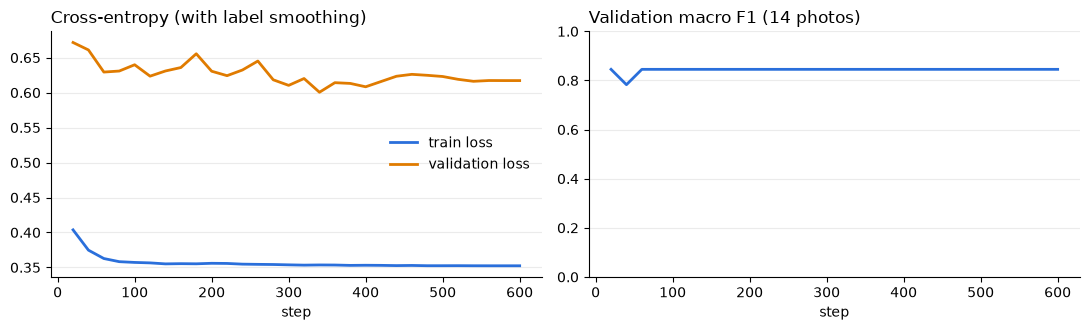

 step  train loss  val loss  val macro F1
  560       0.352     0.617         0.845
  580       0.352     0.617         0.845
  600       0.352     0.617         0.845


In [5]:
tr, va = splits[0]
V = F["dinov2_l"]["tr", "full"]
nn_demo = TorchMLP().fit(np.vstack([V[i] for i in tr]), y[tr], np.vstack([V[i] for i in va]), y[va])
h = pd.DataFrame(nn_demo.history)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.4))
a1.plot(h.step, h["train loss"], lw=2, color="#2a6fdb", label="train loss")
a1.plot(h.step, h["val loss"], lw=2, color="#e07b00", label="validation loss")
a1.set_xlabel("step"); a1.set_title("Cross-entropy (with label smoothing)", loc="left"); a1.legend(frameon=False)
a2.plot(h.step, h["val macro F1"], lw=2, color="#2a6fdb")
a2.set_ylim(0, 1); a2.set_xlabel("step"); a2.set_title("Validation macro F1 (14 photos)", loc="left")
for a in (a1, a2):
    a.spines[["top", "right"]].set_visible(False); a.grid(axis="y", alpha=.25)
plt.tight_layout(); plt.show()
print(h.tail(3).round(3).to_string(index=False))

## 3. Every backbone × view mode × model

Each combination is scored by repeated photo-grouped 5-fold CV. The table reports macro F1 on the 66 original photos
(mean ± std over repeats), the training rows per fold, and the fit time.

In [6]:
oof, results = {}, []
t_all = time.time()
for b, m in FEATURE_SETS:
    V = F[b]["tr", m]
    for name, make in MODELS.items():
        t0 = time.time()
        P = np.zeros((REPEATS, len(train), 4))
        for k, (tr, va) in enumerate(splits):
            P[k // 5, va] = fit_predict(make, [V[i] for i in tr], y[tr], [predict_views(m, V[i]) for i in va])
        P = P[:, orig_idx]
        f1s = [f1_score(y[orig_idx], p.argmax(1), average="macro") for p in P]
        key = f"{b} | {m} | {name}"
        oof[key] = P
        results.append({"backbone": b, "mode": m, "model": name, "CV macro F1": np.mean(f1s), "± std": np.std(f1s),
                        "train rows / fold": int(np.mean([sum(len(V[i]) for i in tr) for tr, _ in splits])),
                        "seconds": round(time.time() - t0, 1), "key": key})
        print(f"{key:55s} F1 {np.mean(f1s):.3f} ± {np.std(f1s):.3f}   ({time.time() - t0:.0f}s)", flush=True)
res = pd.DataFrame(results).sort_values("CV macro F1", ascending=False).reset_index(drop=True)
print(f"\n{len(res)} combinations in {time.time() - t_all:.0f}s")
res.to_csv("logs/model_comparison_notebook_external.csv", index=False)
display(res.drop(columns="key").head(20).style.format({"CV macro F1": "{:.3f}", "± std": "{:.3f}"}))

dinov2_l | full | logistic regression                   F1 0.816 ± 0.033   (0s)


dinov2_l | full | linear SVM                            F1 0.826 ± 0.027   (0s)


dinov2_l | full | RBF SVM                               F1 0.852 ± 0.019   (0s)


dinov2_l | full | kNN (k=5, cosine)                     F1 0.801 ± 0.014   (0s)


dinov2_l | full | extra trees                           F1 0.836 ± 0.008   (3s)


dinov2_l | full | neural net (MLP)                      F1 0.822 ± 0.029   (21s)


... (136 outputs left out)

concat | full | extra trees                             F1 0.813 ± 0.000   (3s)


concat | full | neural net (MLP)                        F1 0.838 ± 0.018   (45s)



144 combinations in 516s


,backbone,mode,model,CV macro F1,± std,train rows / fold,seconds
0,dinov2_l,aug,RBF SVM,0.856,0.015,1403,2.900000
1,dinov2_l,full,RBF SVM,0.852,0.019,63,0.100000
2,dinov2_l,mean7,RBF SVM,0.847,0.013,63,0.100000
3,dinov2_l,fixed7,RBF SVM,0.847,0.025,446,1.000000
4,dinov2_l,fixed7+color+aug,extra trees,0.847,0.025,3955,8.900000
5,dinov2_l,fixed7+color,RBF SVM,0.847,0.025,2679,6.900000
6,dinov2_l,fixed7+aug,RBF SVM,0.847,0.033,1722,4.300000
7,dinov2_l,fixed7+color+aug,RBF SVM,0.847,0.033,3955,12.800000
8,concat,full,RBF SVM,0.847,0.012,63,0.100000
9,siglip_so400m,fixed7+aug,neural net (MLP),0.846,0.013,1722,14.200000


### Best score per model, and the feature set it came from

model,backbone,mode,CV macro F1,± std,train rows / fold
RBF SVM,dinov2_l,aug,0.856,0.015,1403
extra trees,dinov2_l,fixed7+color+aug,0.847,0.025,3955
neural net (MLP),siglip_so400m,fixed7+aug,0.846,0.013,1722
logistic regression,siglip_so400m,aug,0.834,0.019,1403
linear SVM,siglip_so400m,aug,0.829,0.026,1403
"kNN (k=5, cosine)",siglip_so400m,fixed7,0.814,0.013,446


Do crops as training rows help? Mean CV macro F1 per view mode (over backbones with that mode):


mode,full,mean7,fixed7,aug,fixed7+aug,fixed7+color,fixed7+color+aug
model,,,,,,,
RBF SVM,0.799,0.772,0.802,0.823,0.821,0.847,0.847
extra trees,0.774,0.766,0.793,0.831,0.824,0.837,0.847
"kNN (k=5, cosine)",0.762,0.733,0.757,0.780,0.789,0.757,0.757
linear SVM,0.757,0.740,0.776,0.804,0.805,0.794,0.811
logistic regression,0.761,0.751,0.780,0.820,0.812,0.812,0.817
neural net (MLP),0.794,0.783,0.796,0.804,0.811,0.812,0.827


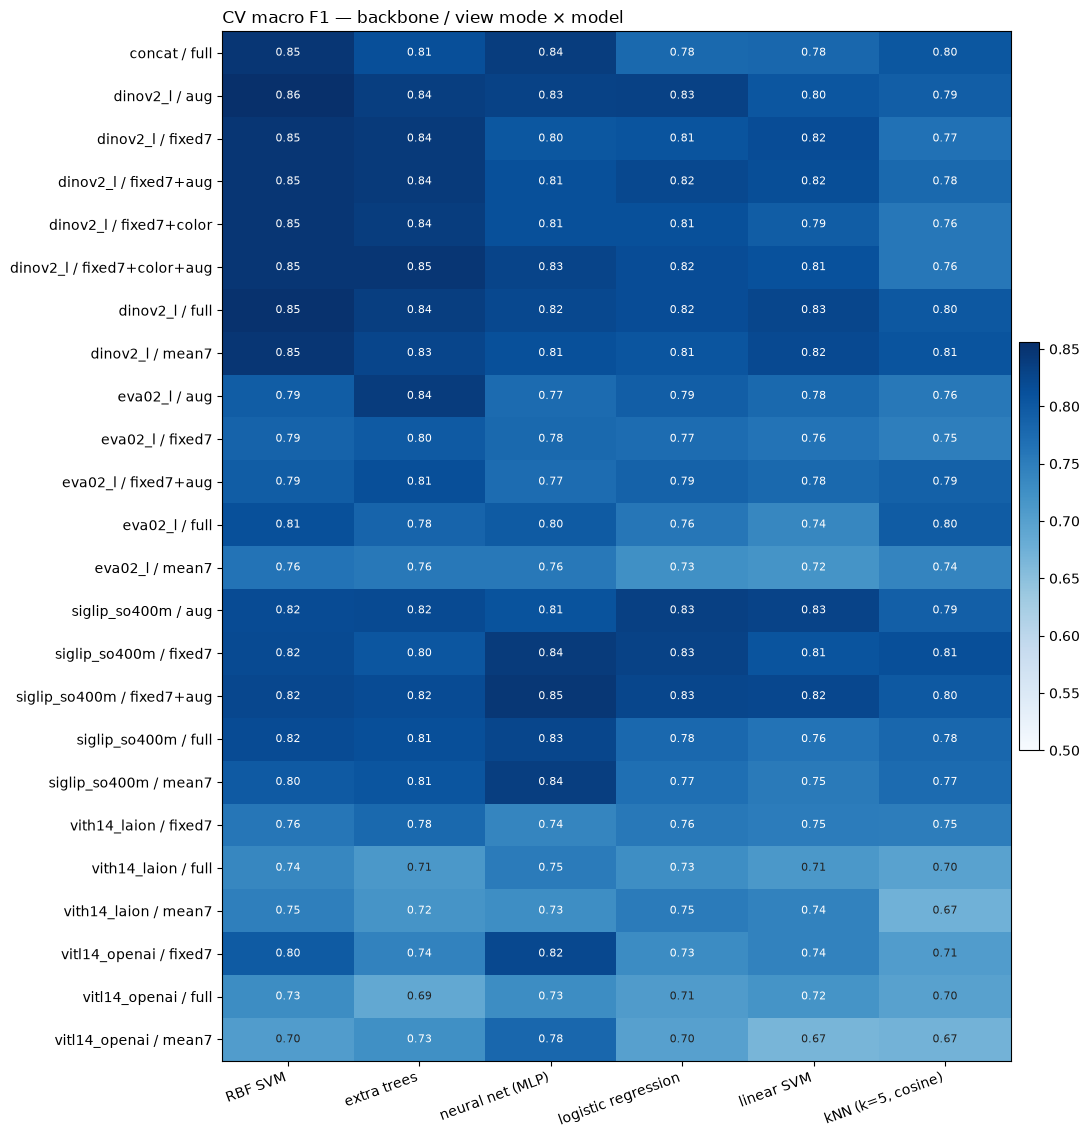

In [7]:
best_per_model = res.loc[res.groupby("model")["CV macro F1"].idxmax()].sort_values("CV macro F1", ascending=False)
display(best_per_model[["model", "backbone", "mode", "CV macro F1", "± std", "train rows / fold"]]
        .style.format({"CV macro F1": "{:.3f}", "± std": "{:.3f}"}).hide(axis="index"))

print("Do crops as training rows help? Mean CV macro F1 per view mode (over backbones with that mode):")
by_mode = res.pivot_table(index="model", columns="mode", values="CV macro F1")[[m for m in MODES if m in set(res["mode"])]]
display(by_mode.style.format("{:.3f}").highlight_max(axis=1, props="font-weight:bold"))

pivot = res.pivot_table(index=["backbone", "mode"], columns="model", values="CV macro F1")
pivot = pivot[best_per_model.model]                     # columns ordered best model first
fig, ax = plt.subplots(figsize=(11, 0.42 * len(pivot) + 1.4))
im = ax.imshow(pivot.values, cmap="Blues", vmin=0.5, vmax=pivot.values.max(), aspect="auto")
ax.set_xticks(range(pivot.shape[1]), pivot.columns, rotation=20, ha="right")
ax.set_yticks(range(len(pivot)), [f"{b} / {m}" for b, m in pivot.index])
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        v = pivot.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                color="white" if v > 0.5 + 0.6 * (pivot.values.max() - 0.5) else "#222")
ax.set_title("CV macro F1 — backbone / view mode × model", loc="left")
fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01)
plt.tight_layout(); plt.show()

## 4. Ensembles

Average the out-of-fold probabilities of several combinations (per CV repeat), then score.

In [8]:
def ens_score(keys):
    P = np.mean([oof[k] for k in keys], axis=0)
    f1s = [f1_score(y[orig_idx], p.argmax(1), average="macro") for p in P]
    return np.mean(f1s), np.std(f1s)

ens_defs = {f"top {k}": list(res.key[:k]) for k in (3, 5, 10)}
ens_defs["best of each model"] = list(best_per_model.key)
ens_defs["neural net, all feature sets"] = list(res.key[res.model == "neural net (MLP)"])
ens_defs["neural net + best RBF SVM + best extra trees"] = [
    best_per_model.key[best_per_model.model == n].item() for n in ("neural net (MLP)", "RBF SVM", "extra trees")]
ens = pd.DataFrame([(n, len(k), *ens_score(k)) for n, k in ens_defs.items()],
                   columns=["ensemble", "members", "CV macro F1", "± std"]).sort_values("CV macro F1", ascending=False)
display(ens.style.format({"CV macro F1": "{:.3f}", "± std": "{:.3f}"}).hide(axis="index"))
print("best single combination:", res.key[0], f"{res['CV macro F1'][0]:.3f}")

ensemble,members,CV macro F1,± std
top 10,10,0.857,0.015
neural net + best RBF SVM + best extra trees,3,0.856,0.015
top 3,3,0.852,0.019
top 5,5,0.852,0.019
best of each model,6,0.841,0.013
"neural net, all feature sets",24,0.822,0.019


best single combination: dinov2_l | aug | RBF SVM 0.856


### Confusion matrix — best single combination vs best ensemble (pooled over CV repeats)

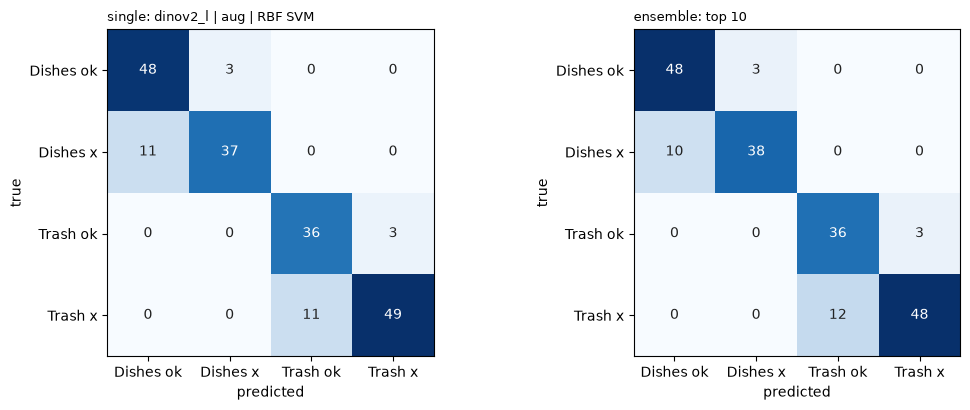

In [9]:
best_ens = ens.ensemble.iloc[0]
show = {f"single: {res.key[0]}": oof[res.key[0]],
        f"ensemble: {best_ens}": np.mean([oof[k] for k in ens_defs[best_ens]], axis=0)}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (title, P) in zip(axes, show.items()):
    cm = sum(confusion_matrix(y[orig_idx], p.argmax(1), labels=range(4)) for p in P)
    ax.imshow(cm, cmap="Blues")
    for i in range(4):
        for j in range(4):
            ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "#222")
    ax.set_xticks(range(4), SHORT); ax.set_yticks(range(4), SHORT)
    ax.set_xlabel("predicted"); ax.set_ylabel("true")
    ax.set_title(title, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

## 5. Refit on all 77 photos (66 + 11 external) and predict the test set

Two files, neither overwrites `submission.csv` (the 0.94155 public file):
- `submission_notebook_external_best.csv` — the best combination overall
- `submission_notebook_external_crops.csv` — the best combination whose training set **includes the cropped images**

In [10]:
ref = pd.read_csv("submission_public0.94155_extratrees.csv").set_index("id").label
best_crop = res[res["mode"].isin(CROP_MODES)].iloc[0]
for row, path in ((res.iloc[0], "submission_notebook_external_best.csv"), (best_crop, "submission_notebook_external_crops.csv")):
    b, m, name = row.backbone, row["mode"], row.model
    V, Vte = F[b]["tr", m], F[b]["te", m]
    P_test = fit_predict(MODELS[name], V, y, [predict_views(m, v) for v in Vte])
    sub = pd.DataFrame({"id": test.id, "label": [CLASSES[k] for k in P_test.argmax(1)]})
    sub.to_csv(path, index=False)
    agree = (sub.set_index("id").label == ref.reindex(sub.id)).mean()
    print(f"{path}: {b} | {m} | {name} — CV {row['CV macro F1']:.3f}, {sum(len(v) for v in V)} training rows, "
          f"agrees with the 0.94155 file on {agree:.0%} of test photos")

submission_notebook_external_best.csv: dinov2_l | aug | RBF SVM — CV 0.856, 1694 training rows, agrees with the 0.94155 file on 86% of test photos


submission_notebook_external_crops.csv: dinov2_l | aug | RBF SVM — CV 0.856, 1694 training rows, agrees with the 0.94155 file on 86% of test photos


## 6. With vs without the external images (same folds, same models)

In [11]:
base = pd.read_csv("logs/model_comparison_notebook.csv").set_index("key")["CV macro F1"]
cmp = res.set_index("key")[["backbone", "mode", "model", "CV macro F1"]].rename(columns={"CV macro F1": "with external"})
cmp["66 photos only"] = base.reindex(cmp.index)
cmp["change"] = cmp["with external"] - cmp["66 photos only"]
print(f"mean change over {len(cmp)} combinations: {cmp.change.mean():+.3f}  |  improved in {(cmp.change > 0).sum()}, worse in {(cmp.change < 0).sum()}")
print(f"best with external: {cmp['with external'].max():.3f}  |  best 66 only: {cmp['66 photos only'].max():.3f}")
display(cmp.pivot_table(index="model", columns="mode", values="change").round(3))
display(cmp.sort_values("with external", ascending=False).head(10).style.format({c: "{:.3f}" for c in ("with external", "66 photos only")} | {"change": "{:+.3f}"}).hide(axis="index"))

mean change over 144 combinations: +0.023  |  improved in 120, worse in 24
best with external: 0.856  |  best 66 only: 0.848


mode,aug,fixed7,fixed7+aug,fixed7+color,fixed7+color+aug,full,mean7
model,,,,,,,
RBF SVM,0.026,0.026,0.035,0.040,0.024,0.020,0.024
extra trees,0.035,0.035,0.032,0.044,0.067,0.002,0.022
"kNN (k=5, cosine)",0.050,0.040,0.048,0.045,0.056,0.019,0.011
linear SVM,0.011,0.011,0.019,0.028,0.039,-0.003,0.032
logistic regression,0.014,0.010,0.019,0.021,0.015,-0.007,-0.000
neural net (MLP),0.031,0.033,0.037,0.041,0.056,0.033,0.044


backbone,mode,model,with external,66 photos only,change
dinov2_l,aug,RBF SVM,0.856,0.838,+0.018
dinov2_l,full,RBF SVM,0.852,0.794,+0.058
dinov2_l,mean7,RBF SVM,0.847,0.794,+0.053
dinov2_l,fixed7,RBF SVM,0.847,0.807,+0.040
dinov2_l,fixed7+color+aug,extra trees,0.847,0.780,+0.067
dinov2_l,fixed7+color,RBF SVM,0.847,0.807,+0.040
dinov2_l,fixed7+aug,RBF SVM,0.847,0.823,+0.024
dinov2_l,fixed7+color+aug,RBF SVM,0.847,0.823,+0.024
concat,full,RBF SVM,0.847,0.812,+0.034
siglip_so400m,fixed7+aug,neural net (MLP),0.846,0.821,+0.025
